In [2]:
import os
os.environ['HF_ENDPOINT'] = 'https://hf-mirror.com'
import pandas as pd
import numpy as np
from Bio.PDB import PDBParser
from transformers import AutoTokenizer, AutoModel
import esm
from scipy.sparse import csr_matrix
import json
import argparse
import time
import re
import requests
from tqdm import tqdm
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModel
from torch_geometric.utils import dense_to_sparse
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, global_mean_pool
from torch_geometric.data import Data,Batch
from torch_geometric.data import HeteroData
from huggingface_hub import hf_hub_download
import pickle
import logging
from sklearn.decomposition import PCA
from utils import get_sequences, seq2rat, pubchem2smiles_batch
import gc
import selfies as sf

In [3]:
DATABASE = 'biosnap'
print('data from: ', DATABASE)
PATH_DTI_FILE = f'../Data/Raw/{DATABASE}_dtis_pubchem_uniprot.tsv'
dti = pd.read_csv(PATH_DTI_FILE, sep='\t')
dti['Drug'] = dti.Drug.astype(str) # safety
# Output path
OUTPUT_PATH = f'../Data/{DATABASE.upper()}'

data from:  biosnap


In [4]:
dti

,Drug,Protein
0,2145,P05108
1,77022,P00325
2,36462,P23219
3,3038525,Q16539
4,24864077,P24941
...,...,...
13874,5472,P10635
13875,3261,P47870
13876,6077,P21728
13877,71616,P08684


In [5]:
# 从LLM文件夹直接加载EMS-2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, alphabet = esm.pretrained.load_model_and_alphabet_local('../LLM/esm2_t33_650M_UR50D.pt')
batch_converter = alphabet.get_batch_converter()
model = model.to(device)
model.eval()

E:\Anaconda\envs\pytorch\lib\site-packages\esm\pretrained.py:70: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_data = torch.load(str(model_location), map_location="cpu

ESM2(
  (embed_tokens): Embedding(33, 1280, padding_idx=1)
  (layers): ModuleList(
    (0-32): 33 x TransformerLayer(
      (self_attn): MultiheadAttention(
        (k_proj): Linear(in_features=1280, out_features=1280, bias=True)
        (v_proj): Linear(in_features=1280, out_features=1280, bias=True)
        (q_proj): Linear(in_features=1280, out_features=1280, bias=True)
        (out_proj): Linear(in_features=1280, out_features=1280, bias=True)
        (rot_emb): RotaryEmbedding()
      )
      (self_attn_layer_norm): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
      (fc1): Linear(in_features=1280, out_features=5120, bias=True)
      (fc2): Linear(in_features=5120, out_features=1280, bias=True)
      (final_layer_norm): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
    )
  )
  (contact_head): ContactPredictionHead(
    (regression): Linear(in_features=660, out_features=1, bias=True)
    (activation): Sigmoid()
  )
  (emb_layer_norm_after): LayerNorm((1280,), eps=1

In [6]:
# ems-2转化成一维向量
def batch_seq_embedding(sequences, batch_size=64):
    """
    sequences: list[str]  蛋白质序列列表
    batch_size: 每次送入 GPU 的批大小
    返回: list[np.ndarray] (每条序列一个 320 维向量)
    """
    embeddings = []
    for i in range(0, len(sequences), batch_size):
        batch = sequences[i:i+batch_size]
        data = [(str(idx), seq) for idx, seq in enumerate(batch)]
        batch_labels, batch_strs, batch_tokens = batch_converter(data)
        batch_tokens = batch_tokens.to(device)

        with torch.no_grad():
            results = model(batch_tokens, repr_layers=[6])
            reps = results["representations"][6][:, 0, :]  # CLS token

        for j in range(len(batch)):
            embeddings.append(reps[j].cpu().numpy())

    return embeddings

In [7]:
# 每个数据集只用运行一次第二次直接从底下文件夹拿goto
proteins_unique = dti.Protein.unique().tolist()
protein_features = pd.DataFrame(proteins_unique,columns = ['Uniprot'])
logging.debug('Retrieving sequences...')
prot2seq = get_sequences(proteins_unique)

Retrieving uniprot sequence: 100%|██████████| 6/6 [03:14<00:00, 32.38s/it]


In [8]:
protein_features['Sequence'] = protein_features.Uniprot.map(prot2seq)
protein_features = protein_features.dropna() # safety
MAX_LEN = 1024
protein_features['Sequence'] = protein_features['Sequence'].map(
    lambda x: x[:MAX_LEN]
)
sequence=protein_features['Sequence'].tolist()
protein_features['Embedding'] = batch_seq_embedding(sequence,batch_size=1)
available_proteins = protein_features.Uniprot.unique().tolist()
protein_features.head(3)

,Uniprot,Sequence,Embedding
0,P05108,MLAKGLPPRSVLVKGCQTFLSAPREGLGRLRVPTGEGAGISTRSPR...,"[-0.84954536, 0.12892759, 1.070866, 0.66949195..."
1,P00325,MSTAGKVIKCKAAVLWEVKKPFSIEDVEVAPPKAYEVRIKMVAVGI...,"[0.37987185, 0.44895247, 0.15855315, -0.116382..."
2,P23219,MSRSLLLWFLLFLLLLPPLPVLLADPGAPTPVNPCCYYPCQHQGIC...,"[-0.7846335, 1.4728255, -1.6888254, 0.39127415..."


In [9]:
# 把这个处理好的数据存储在protein_features文件夹里面的对应文件夹里
# 创建这个存储文件夹
output_dir = f"../Data/protein_features/{DATABASE}"
os.makedirs(output_dir, exist_ok=True)


In [10]:
## here
with open(f'{output_dir}/protein_features.pkl', "wb") as f:
    pickle.dump(protein_features, f)
with open(f'{output_dir}/protein_features.pkl', "rb") as f:
    protein_features = pickle.load(f)
protein_features.head(3)

,Uniprot,Sequence,Embedding
0,P05108,MLAKGLPPRSVLVKGCQTFLSAPREGLGRLRVPTGEGAGISTRSPR...,"[-0.84954536, 0.12892759, 1.070866, 0.66949195..."
1,P00325,MSTAGKVIKCKAAVLWEVKKPFSIEDVEVAPPKAYEVRIKMVAVGI...,"[0.37987185, 0.44895247, 0.15855315, -0.116382..."
2,P23219,MSRSLLLWFLLFLLLLPPLPVLLADPGAPTPVNPCCYYPCQHQGIC...,"[-0.7846335, 1.4728255, -1.6888254, 0.39127415..."


In [11]:
# 使用alphafold搞出蛋白质的PDB三D结构
uniprot_ids =protein_features['Uniprot'].tolist()
save_dir = os.path.join("..", "Data", "PDB", DATABASE)
os.makedirs(save_dir, exist_ok=True)

In [12]:
def download_alphafold_pdb(uniprot_ids):
    """
    使用 AlphaFold 下载指定 Uniprot ID 的预测结构（PDB 文件）。

    参数:
        uniprot_ids (list of str): Uniprot ID 列表
        database_name (str): 数据库名称，用于创建子文件夹
        save_root (str): PDB 文件保存根目录
    """
    for uid in uniprot_ids:
        pdb_filename = f"{uid}.pdb"
        save_path = os.path.join(save_dir, pdb_filename)

        if os.path.exists(save_path):
            print(f"{uid} already exists, skipping...")
            continue

        url = f"https://alphafold.ebi.ac.uk/files/AF-{uid}-F1-model_v6.pdb"

        try:
            response = requests.get(url, timeout=20)
            response.raise_for_status()
            with open(save_path, 'w') as f:
                f.write(response.text)
            print(f"{uid} AlphaFold PDB downloaded successfully!")
        except requests.exceptions.RequestException as e:
            print(f"❌ Failed to download {uid}: {e}")

In [13]:
download_alphafold_pdb(uniprot_ids)

P05108 AlphaFold PDB downloaded successfully!
P00325 AlphaFold PDB downloaded successfully!
P23219 AlphaFold PDB downloaded successfully!
Q16539 AlphaFold PDB downloaded successfully!
P24941 AlphaFold PDB downloaded successfully!
P23975 AlphaFold PDB downloaded successfully!
P08173 AlphaFold PDB downloaded successfully!
P48169 AlphaFold PDB downloaded successfully!
P10635 AlphaFold PDB downloaded successfully!
P08913 AlphaFold PDB downloaded successfully!
P05023 AlphaFold PDB downloaded successfully!
P07477 AlphaFold PDB downloaded successfully!
P08254 AlphaFold PDB downloaded successfully!
P18031 AlphaFold PDB downloaded successfully!
P21549 AlphaFold PDB downloaded successfully!
P21266 AlphaFold PDB downloaded successfully!
P10632 AlphaFold PDB downloaded successfully!
P08684 AlphaFold PDB downloaded successfully!
P34903 AlphaFold PDB downloaded successfully!
Q14534 AlphaFold PDB downloaded successfully!
P33261 AlphaFold PDB downloaded successfully!
P04035 AlphaFold PDB downloaded su

In [14]:
# 过滤掉没有PDB的
output_dir = f"../Data/protein_features/{DATABASE}"
os.makedirs(output_dir, exist_ok=True)
with open(f'{output_dir}/protein_features.pkl', "rb") as f:
    protein_features = pickle.load(f)
print(f"原始蛋白数量: {len(protein_features)}")
pdb_dir = f"../Data/PDB/{DATABASE}"
pdb_files = os.listdir(pdb_dir)
pdb_uniprot_ids = set([f.split(".")[0] for f in pdb_files if f.endswith(".pdb")])
cleaned_features = protein_features[
    protein_features["Uniprot"].isin(pdb_uniprot_ids)
].reset_index(drop=True)
print("过滤后蛋白数量:", len(cleaned_features))
with open(f'{output_dir}/protein_features_filtered.pkl', "wb") as f:
    pickle.dump(cleaned_features,f)
print("✔ 已保存到 protein_features_filtered.pkl")

原始蛋白数量: 2113
过滤后蛋白数量: 2078
✔ 已保存到 protein_features_filtered.pkl


In [15]:
with open(f'{output_dir}/protein_features_filtered.pkl', "rb") as f:
    protein_features = pickle.load(f)
protein_features.head(3)

,Uniprot,Sequence,Embedding
0,P05108,MLAKGLPPRSVLVKGCQTFLSAPREGLGRLRVPTGEGAGISTRSPR...,"[-0.84954536, 0.12892759, 1.070866, 0.66949195..."
1,P00325,MSTAGKVIKCKAAVLWEVKKPFSIEDVEVAPPKAYEVRIKMVAVGI...,"[0.37987185, 0.44895247, 0.15855315, -0.116382..."
2,P23219,MSRSLLLWFLLFLLLLPPLPVLLADPGAPTPVNPCCYYPCQHQGIC...,"[-0.7846335, 1.4728255, -1.6888254, 0.39127415..."


In [16]:
aa_codes = {
    'ALA': 'A', 'CYS': 'C', 'ASP': 'D', 'GLU': 'E',
    'PHE': 'F', 'GLY': 'G', 'HIS': 'H', 'LYS': 'K',
    'ILE': 'I', 'LEU': 'L', 'MET': 'M', 'ASN': 'N',
    'PRO': 'P', 'GLN': 'Q', 'ARG': 'R', 'SER': 'S',
    'THR': 'T', 'VAL': 'V', 'TYR': 'Y', 'TRP': 'W',
}
def get_center_atom(residue):
    """选择用于计算距离的原子"""
    for atom_name in ['CA','N','C','O','CB','CD','CG']:
        if residue.has_id(atom_name):
            return atom_name
    raise ValueError(f"No suitable atom found in residue {residue}")

def calc_residue_dist(residue_one, residue_two):
    """计算两个残基的欧氏距离"""
    c_atom1 = get_center_atom(residue_one)
    c_atom2 = get_center_atom(residue_two)
    diff_vector = residue_one[c_atom1].coord - residue_two[c_atom2].coord
    return np.sqrt(np.sum(diff_vector * diff_vector))

def calc_dist_matrix(chain_one, chain_two):
    """计算两个链之间残基距离矩阵"""
    residues_one = [res for res in chain_one if res.get_id()[0] == " " and res.get_resname() in aa_codes]
    residues_two = [res for res in chain_two if res.get_id()[0] == " " and res.get_resname() in aa_codes]

    n = len(residues_one)
    m = len(residues_two)
    matrix = np.zeros((n, m), dtype=np.float32)

    for i, res1 in enumerate(residues_one):
        for j, res2 in enumerate(residues_two):
            matrix[i, j] = calc_residue_dist(res1, res2)

    # 对角线标记为 100
    for i in range(min(n, m)):
        matrix[i, i] = 100
    return matrix

def calc_contact_map(pdb_file, chain_id='A', threshold=8.0):
    """生成 contact map"""
    structure = PDBParser().get_structure(os.path.basename(pdb_file), pdb_file)
    model = structure[0]
    if chain_id not in model:
        raise ValueError(f"Chain {chain_id} not found in {pdb_file}")
    dist_matrix = calc_dist_matrix(model[chain_id], model[chain_id])
    contact_map = (dist_matrix < threshold).astype(np.int_)
    return contact_map

In [17]:
data_path = os.path.join('../Data/PDB', DATABASE)  # 输入 PDB 文件目录
output_path_base = os.path.join('../Data/contact_maps', DATABASE)  # 输出 contact map 目录
os.makedirs(output_path_base, exist_ok=True)
pdb_files = [f for f in os.listdir(data_path) if f.endswith('.pdb')]
for pdb_file in pdb_files:
    pdb_path = os.path.join(data_path, pdb_file)
    try:
        cm = calc_contact_map(pdb_path, chain_id='A', threshold=8.0)
        output_path = os.path.join(output_path_base, pdb_file.replace('.pdb', '_contact_map.npy'))
        np.save(output_path, cm)
        print(f"{pdb_file} -> contact map saved: {output_path}")
    except Exception as e:
        print(f"❌ Failed to process {pdb_file}: {e}")

A5X5Y0.pdb -> contact map saved: ../Data/contact_maps\biosnap\A5X5Y0_contact_map.npy
A8MPY1.pdb -> contact map saved: ../Data/contact_maps\biosnap\A8MPY1_contact_map.npy
O00141.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00141_contact_map.npy
O00142.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00142_contact_map.npy
O00180.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00180_contact_map.npy
O00182.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00182_contact_map.npy
O00187.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00187_contact_map.npy
O00204.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00204_contact_map.npy
O00206.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00206_contact_map.npy
O00217.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00217_contact_map.npy
O00222.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00222_contact_map.npy
O00244.pdb -> contact map saved: ../Data/contact_maps\biosnap\O00

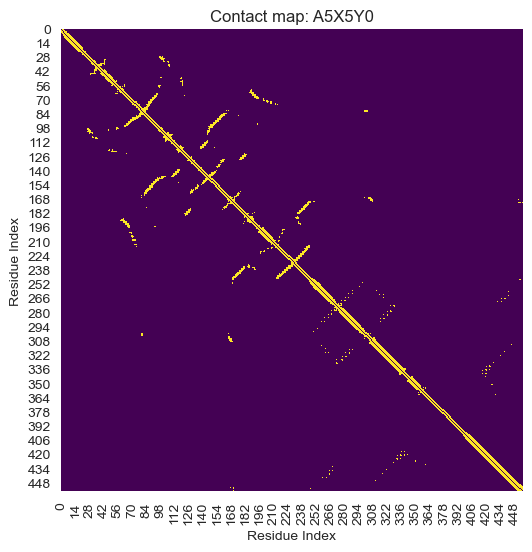

In [18]:
contact_map_dir = os.path.join('../Data/contact_maps', DATABASE)
contact_map_files = [f for f in os.listdir(contact_map_dir) if f.endswith('.npy')]
contact_map_files.sort()  # 排序，方便选择第一个
if len(contact_map_files) == 0:
    raise ValueError("没有找到 contact map 文件，请先生成")
# 选择第一个 contact map 文件
cm_file = contact_map_files[0]
cm_path = os.path.join(contact_map_dir, cm_file)
contact_map = np.load(cm_path)
plt.figure(figsize=(6,6))
sns.heatmap(contact_map, cmap='viridis', square=True, cbar=False)
plt.title(f"Contact map: {cm_file.replace('_contact_map.npy','')}")
plt.xlabel('Residue Index')
plt.ylabel('Residue Index')
plt.show()

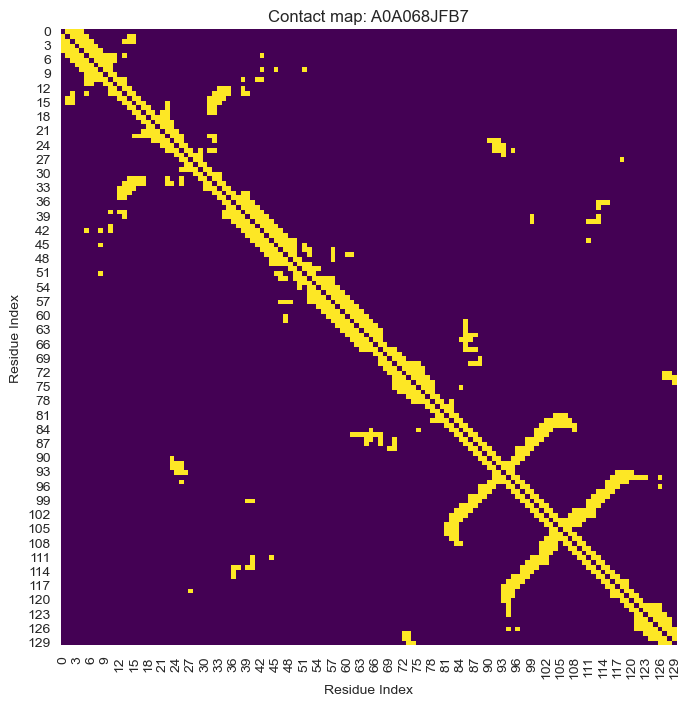

✅ 接触矩阵图片已保存到: ../image\drugbank\A0A068JFB7.png


In [48]:
# ... existing code ...
contact_map_dir = os.path.join('../Data/contact_maps', DATABASE)
output_image_dir = os.path.join('../image', DATABASE)
os.makedirs(output_image_dir, exist_ok=True)

contact_map_files = [f for f in os.listdir(contact_map_dir) if f.endswith('.npy')]
contact_map_files.sort()

if len(contact_map_files) == 0:
    raise ValueError("没有找到 contact map 文件，请先生成")

# 选择第一个 contact map 文件
cm_file = contact_map_files[2]
cm_path = os.path.join(contact_map_dir, cm_file)
contact_map = np.load(cm_path)

plt.figure(figsize=(8, 8))
sns.heatmap(contact_map, cmap='viridis', square=True, cbar=False)
plt.title(f"Contact map: {cm_file.replace('_contact_map.npy','')}", fontsize=12)
plt.xlabel('Residue Index')
plt.ylabel('Residue Index')

# 保存图片
image_path = os.path.join(output_image_dir, f"{cm_file.replace('_contact_map.npy', '')}.png")
plt.savefig(image_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 接触矩阵图片已保存到: {image_path}")
# ... existing code ...


In [19]:
# 接触矩阵降维
DATABASE = "biosnap"   # 你可以修改
input_dir = f"../Data/contact_maps/{DATABASE}"
output_dir = f"../Data/contact_maps_emb/{DATABASE}"
os.makedirs(output_dir, exist_ok=True)

In [20]:
# 构造一个针对同质生物图的GIN
class ContactMapGIN(torch.nn.Module):
    def __init__(self, node_dim=1, hidden=64, out_dim=128):
        super().__init__()

        nn1 = torch.nn.Sequential(
            torch.nn.Linear(node_dim, hidden),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden, hidden)
        )
        nn2 = torch.nn.Sequential(
            torch.nn.Linear(hidden, hidden),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden, out_dim)
        )

        self.conv1 = GINConv(nn1)
        self.conv2 = GINConv(nn2)

    def forward(self, x, edge_index, batch):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        out = global_mean_pool(x, batch)  # [1, out_dim]
        return out

In [22]:
# ... existing code ...
import gc
import re

# 1. 预加载蛋白质特征 (ESM-2 Embeddings)
pkl_path = f"../Data/protein_features/{DATABASE}/protein_features_filtered.pkl"
with open(pkl_path, "rb") as f:
    protein_df = pickle.load(f)

# 建立映射: Uniprot ID -> Embedding (numpy array)
uniprot2emb = dict(zip(protein_df['Uniprot'], protein_df['Embedding']))
print(f"✔ 已预加载 {len(uniprot2emb)} 个蛋白质的 ESM-2 特征 (维度: 1280)")

# 2. 初始化 GIN 模型 (关键：node_dim 必须设为 1280)
model = ContactMapGIN(node_dim=1280).to(device)
model.eval()

results = {}
input_dir = f"../Data/contact_maps/{DATABASE}"
output_dir = f"../Data/contact_maps_emb/{DATABASE}"
os.makedirs(output_dir, exist_ok=True)

all_files = [f for f in os.listdir(input_dir) if f.endswith(".npy")]
print(f"🚀 开始处理 {len(all_files)} 个接触矩阵...")

for idx, filename in enumerate(all_files):
    # 3. 智能提取 Uniprot ID
    # 尝试匹配标准 Uniprot 格式 (如 P12345, Q9Y2X1)
    match = re.search(r'([A-N,R-Z][0-9][A-Z]{3}[0-9])', filename)
    uniprot_id = match.group(1) if match else filename.split("_")[0]

    if uniprot_id not in uniprot2emb:
        continue

    # 4. 构造带有语义信息的节点特征 x
    esm_feat = uniprot2emb[uniprot_id]  # (1280,)
    path = os.path.join(input_dir, filename)
    contact_map = np.load(path)
    N = contact_map.shape[0]

    # 优化点：将全局向量复制 N 次，形成 (N, 1280) 的节点特征矩阵
    # 这样每个氨基酸节点都拥有了该蛋白质的全局进化背景
    x = torch.tensor(np.tile(esm_feat, (N, 1)), dtype=torch.float32).to(device)

    # 5. 图结构转换
    edge_index, _ = dense_to_sparse(torch.tensor(contact_map, dtype=torch.float32).to(device))
    batch = torch.zeros(N, dtype=torch.long, device=device)

    # 6. GIN 推理
    with torch.no_grad():
        try:
            emb = model(x, edge_index, batch).cpu().numpy()

            save_name = filename.replace(".npy", "_gin_emb.npy")
            np.save(os.path.join(output_dir, save_name), emb)
            results[filename] = save_name

            if (idx + 1) % 50 == 0:
                print(f"进度: {idx + 1}/{len(all_files)}, 当前形状: {emb.shape}")
        except Exception as e:
            print(f"❌ Error processing {filename}: {e}")

    # 7. 显存维护 (针对 8GB 显卡的必要操作)
    if idx % 10 == 0:
        torch.cuda.empty_cache()

# 保存索引
with open(os.path.join(output_dir, "index.pkl"), "wb") as f:
    pickle.dump(results, f)

print("\n🎉 Processing complete! Results saved to:", output_dir)

✔ 已预加载 2078 个蛋白质的 ESM-2 特征 (维度: 1280)
🚀 开始处理 2078 个接触矩阵...
进度: 50/2078, 当前形状: (1, 128)
进度: 100/2078, 当前形状: (1, 128)
进度: 150/2078, 当前形状: (1, 128)
进度: 200/2078, 当前形状: (1, 128)
进度: 250/2078, 当前形状: (1, 128)
进度: 300/2078, 当前形状: (1, 128)
进度: 350/2078, 当前形状: (1, 128)
进度: 400/2078, 当前形状: (1, 128)
进度: 450/2078, 当前形状: (1, 128)
进度: 500/2078, 当前形状: (1, 128)
进度: 550/2078, 当前形状: (1, 128)
进度: 600/2078, 当前形状: (1, 128)
进度: 650/2078, 当前形状: (1, 128)
进度: 700/2078, 当前形状: (1, 128)
进度: 750/2078, 当前形状: (1, 128)
进度: 800/2078, 当前形状: (1, 128)
进度: 850/2078, 当前形状: (1, 128)
进度: 900/2078, 当前形状: (1, 128)
进度: 950/2078, 当前形状: (1, 128)
进度: 1000/2078, 当前形状: (1, 128)
进度: 1050/2078, 当前形状: (1, 128)
进度: 1100/2078, 当前形状: (1, 128)
进度: 1150/2078, 当前形状: (1, 128)
进度: 1200/2078, 当前形状: (1, 128)
进度: 1250/2078, 当前形状: (1, 128)
进度: 1300/2078, 当前形状: (1, 128)
进度: 1350/2078, 当前形状: (1, 128)
进度: 1400/2078, 当前形状: (1, 128)
进度: 1450/2078, 当前形状: (1, 128)
进度: 1500/2078, 当前形状: (1, 128)
进度: 1550/2078, 当前形状: (1, 128)
进度: 1600/2078, 当前形状: (1, 128)
进

In [11]:
# ... existing code ...
# 不知道为什么跑这来了
drug_features_dir = f'../Data/drug_features/{DATABASE}'
protein_features_dir = f'../Data/protein_features/{DATABASE}'
drug_features_path = f'{drug_features_dir}/drug_features.pkl'
with open(drug_features_path, 'rb') as f:
    drug_features = pickle.load(f)
DTI_PATH = f'../Data/DTI/{DATABASE}/dit_filter.pkl'
dti = pd.read_pickle(DTI_PATH)
print(f"已加载 DTI 数据: {dti.shape}")
def safe_smiles_to_selfies(smiles):
    """安全地将 SMILES 转换为 SELFIES"""
    try:
        if pd.isna(smiles) or smiles == '':
            return None
        return sf.encoder(str(smiles))
    except Exception as e:
        print(f"⚠️ 转换失败: {smiles[:50]} | Error: {str(e)[:100]}")
        return None

drug_features['SELFIES'] = drug_features['SMILES'].apply(safe_smiles_to_selfies)

# 统计并过滤转换失败的
failed_mask = drug_features['SELFIES'].isna()
failed_count = failed_mask.sum()
print(f"\n❌ SELFIES 转换失败: {failed_count}/{len(drug_features)}")

if failed_count > 0:
    # 获取失败的药物 ID
    failed_drugs = set(drug_features[failed_mask]['PubChem'].astype(str))
    print(f"失败的药物数量: {len(failed_drugs)}")

    # 从 drug_features 中剔除
    drug_features_before = len(drug_features)
    drug_features = drug_features.dropna(subset=['SELFIES']).reset_index(drop=True)
    print(f"✔ drug_features 过滤: {drug_features_before} -> {len(drug_features)}")

    # 从原始 DTI 中剔除这些药物对应的所有记录
    dti_filtered = dti[~dti['Drug'].astype(str).isin(failed_drugs)]
    print(f"✔ DTI 过滤: {len(dti)} -> {len(dti_filtered)} (剔除 {len(dti) - len(dti_filtered)} 条)")

    # 保存过滤后的 DTI
    output_dir = f"../Data/DTI/{DATABASE}"
    os.makedirs(output_dir, exist_ok=True)
    dti_filtered.to_pickle(f'{output_dir}/dti_filter.pkl')
    print(f"✔ 已保存过滤后的 DTI")
else:
    print("✅ 所有药物转换成功")
    dti_filtered = dti.copy()

# 保存 drug_features
drug_features.to_pickle(f'{drug_features_dir}/drug_features_SELFIES.pkl')
print(f"✔ 已保存到: {drug_features_dir}/drug_features_SELFIES.pkl")

# 从 protein_features 中剔除在 DTI 中不再出现的蛋白质
available_proteins_in_dti = set(dti_filtered['Protein'].unique())
protein_features_before = len(protein_features)
protein_features_filtered = protein_features[protein_features['Uniprot'].isin(available_proteins_in_dti)].reset_index(drop=True)
print(f"✔ protein_features 过滤: {protein_features_before} -> {len(protein_features_filtered)} (剔除 {protein_features_before - len(protein_features_filtered)} 个蛋白质)")

# 更新 protein_features
protein_features = protein_features_filtered

# 保存更新后的 protein_features（如果需要覆盖原文件）
protein_features_path = f'{protein_features_dir}/protein_features_fused.pkl'
with open(protein_features_path, "wb") as f:
    pickle.dump(protein_features, f)
print(f"✔ 已更新保存到: {protein_features_path}")

drug_features
# ... existing code ...


已加载 DTI 数据: (23535, 2)
⚠️ 转换失败: [O-]Cl(=O)(=O)=O | Error: input violates the currently-set semantic constraints
	SMILES: [O-]Cl(=O)(=O)=O
	Errors:
	[Cl with 7
⚠️ 转换失败: O.[O-]Cl=O.[O-]Cl=O.[O-]Cl=O.[O-]Cl=O.O=O | Error: input violates the currently-set semantic constraints
	SMILES: O.[O-]Cl=O.[O-]Cl=O.[O-]Cl=O.[O-]Cl=O

❌ SELFIES 转换失败: 2/5449
失败的药物数量: 2
✔ drug_features 过滤: 5449 -> 5447
✔ DTI 过滤: 23535 -> 23532 (剔除 3 条)
✔ 已保存过滤后的 DTI
✔ 已保存到: ../Data/drug_features/drugbank/drug_features_SELFIES.pkl
✔ protein_features 过滤: 4422 -> 4420 (剔除 2 个蛋白质)
✔ 已更新保存到: ../Data/protein_features/drugbank/protein_features_fused.pkl


,PubChem,SMILES,SELFIES
0,16129704,CCC(C)C(C(=O)N1CCCC1C(=O)NC(CCC(=O)O)C(=O)NC(C...,[C][C][C][Branch1][C][C][C][Branch2][=Branch1]...
1,5311128,CC(C)CC(C(=O)NC(CCCN=C(N)N)C(=O)N1CCCC1C(=O)NN...,[C][C][Branch1][C][C][C][C][Branch2][Ring2][Br...
2,45267103,CC(C)CC(C(=O)NC(C)C(=O)NC(C(C)C)C(=O)NC(C(C)C)...,[C][C][Branch1][C][C][C][C][Branch2][=N][O][C]...
3,25074887,CC(C)CC(C(=O)NC(CCCN=C(N)N)C(=O)N1CCCC1C(=O)NC...,[C][C][Branch1][C][C][C][C][Branch2][Ring2][O]...
4,16134395,CCCCCCCCCC(=O)NC(CC1=CNC2=CC=CC=C21)C(=O)NC(CC...,[C][C][C][C][C][C][C][C][C][C][=Branch1][C][=O...
...,...,...,...
5442,6323420,CC(C)(C)C1=CC(=NNC2=CC=CC=C2C(=O)O)C=CC1=O,[C][C][Branch1][C][C][Branch1][C][C][C][=C][C]...
5443,40428878,CC1(C=C(C(N1O)(C)C)CSS(=O)(=O)C)C,[C][C][Branch2][Ring1][#Branch2][C][=C][Branch...
5444,11987556,C1C=NC(=NC2=CC(=CC=C2)[N+](=O)[O-])N=C1C3=CC=C...,[C][C][=N][C][=Branch1][P][=N][C][=C][C][=Bran...
5445,11840966,CC1=C(SC(=N1)N)C2=NC(=NC3=CC=C(C=C3)N4CCOCC4)N...,[C][C][=C][Branch1][=Branch2][S][C][=Branch1][...


In [23]:
# ... existing code ...
import re

# 1. 加载原始的蛋白质特征表
pkl_path = f"../Data/protein_features/{DATABASE}/protein_features_filtered.pkl"
with open(pkl_path, "rb") as f:
    protein_df = pickle.load(f)

# 2. 加载 GIN 提取结果的索引
gin_index_path = f"../Data/contact_maps_emb/{DATABASE}/index.pkl"
if not os.path.exists(gin_index_path):
    raise FileNotFoundError("请先运行上一段 GIN 代码生成 index.pkl")

with open(gin_index_path, "rb") as f:
    gin_results = pickle.load(f)

print(f"✔ 已加载 {len(gin_results)} 个蛋白质的 GIN 结构特征索引")

# 3. 建立 Uniprot -> GIN_Embedding 的映射
uniprot2gin = {}
# 关键修复：获取存放 .npy 文件的绝对目录
emb_base_dir = f"../Data/contact_maps_emb/{DATABASE}"

for filename, emb_path in gin_results.items():
    # 从文件名中提取 Uniprot ID
    match = re.search(r'([A-N,R-Z][0-9][A-Z]{3}[0-9])', filename)
    uniprot_id = match.group(1) if match else filename.split("_")[0]

    # 关键修复：拼接完整路径
    # 如果 emb_path 只是文件名，就拼接；如果是完整路径则直接使用
    if not os.path.isabs(emb_path):
        full_path = os.path.join(emb_base_dir, emb_path)
    else:
        full_path = emb_path

    try:
        # 加载 .npy 文件
        gin_vec = np.load(full_path)
        uniprot2gin[uniprot_id] = gin_vec
    except Exception as e:
        print(f"⚠️ 无法加载 {full_path}: {e}")

# 4. 将 GIN 特征添加到 DataFrame 的第四列
protein_df['Concat_map'] = protein_df['Uniprot'].map(uniprot2gin)

# 检查匹配情况
missing = protein_df['Concat_map'].isna().sum()
print(f"⚠️ 有 {missing} 个蛋白质未找到对应的 GIN 特征")
print(f"✅ 成功匹配 {len(protein_df) - missing} 个")

# 5. 保存更新后的表格
output_dir = f"../Data/protein_features/{DATABASE}"
save_path = f"{output_dir}/protein_features_final.pkl"
with open(save_path, "wb") as f:
    pickle.dump(protein_df, f)

print(f"✔ 已保存到: {save_path}")
print("表格前几行预览：")
print(protein_df.head())


✔ 已加载 2078 个蛋白质的 GIN 结构特征索引
⚠️ 有 0 个蛋白质未找到对应的 GIN 特征
✅ 成功匹配 2078 个
✔ 已保存到: ../Data/protein_features/biosnap/protein_features_final.pkl
表格前几行预览：
  Uniprot                                           Sequence  \
0  P05108  MLAKGLPPRSVLVKGCQTFLSAPREGLGRLRVPTGEGAGISTRSPR...   
1  P00325  MSTAGKVIKCKAAVLWEVKKPFSIEDVEVAPPKAYEVRIKMVAVGI...   
2  P23219  MSRSLLLWFLLFLLLLPPLPVLLADPGAPTPVNPCCYYPCQHQGIC...   
3  Q16539  MSQERPTFYRQELNKTIWEVPERYQNLSPVGSGAYGSVCAAFDTKT...   
4  P24941  MENFQKVEKIGEGTYGVVYKARNKLTGEVVALKKIRLDTETEGVPS...   

                                           Embedding  \
0  [-0.84954536, 0.12892759, 1.070866, 0.66949195...   
1  [0.37987185, 0.44895247, 0.15855315, -0.116382...   
2  [-0.7846335, 1.4728255, -1.6888254, 0.39127415...   
3  [-0.4034434, -0.4669195, 0.29901224, 0.4281491...   
4  [0.24496272, -0.15595862, 0.6181825, -0.670532...   

                                          Concat_map  
0  [[-14.348771, -10.711589, -0.35536388, -5.1508...  
1  [[-24.4858, -17.02956

In [24]:

output_dir=f"../Data/protein_features/{DATABASE}"
save_path = f"{output_dir}/protein_features_final.pkl"
with open(save_path, "rb") as f:
    protein_features=pickle.load(f)
emb_list = np.vstack(protein_features["Embedding"].values)
pca = PCA(n_components=256)
# 128 88.37%损失度大不太能接收,256就是95.80%可以接受
# drugbank 89.84%
# biosnap 91.15%
emb_128 = pca.fit_transform(emb_list)
print(f"PCA 降维信息保留率: {pca.explained_variance_ratio_.sum():.4f} ({pca.explained_variance_ratio_.sum()*100:.2f}%)")
protein_features["Embedding_256"] = list(emb_128)
protein_features = protein_features.drop(columns=['Embedding'])
output_path = f"{output_dir}/protein_features_final_v2.pkl"
with open(output_path, "wb") as f:
    pickle.dump(protein_features, f)
print(f"✔ Embedding 降维并保存到: {output_path}")
protein_features[:3]

PCA 降维信息保留率: 0.9115 (91.15%)
✔ Embedding 降维并保存到: ../Data/protein_features/biosnap/protein_features_final_v2.pkl


,Uniprot,Sequence,Concat_map,Embedding_256
0,P05108,MLAKGLPPRSVLVKGCQTFLSAPREGLGRLRVPTGEGAGISTRSPR...,"[[-14.348771, -10.711589, -0.35536388, -5.1508...","[-11.7063265, 1.0197208, -3.8710518, -6.560757..."
1,P00325,MSTAGKVIKCKAAVLWEVKKPFSIEDVEVAPPKAYEVRIKMVAVGI...,"[[-24.4858, -17.029562, 5.9996953, -15.521619,...","[-5.346238, -7.897728, 0.6151404, 10.712676, 1..."
2,P23219,MSRSLLLWFLLFLLLLPPLPVLLADPGAPTPVNPCCYYPCQHQGIC...,"[[-16.259535, -12.707548, -11.063495, -9.09824...","[16.019188, 3.069349, -8.078151, -5.7106643, -..."


In [55]:
# 1. 提取两列特征并转换为 numpy 数组堆叠
# 会出现二维缺失问题,直接用0补位
emb_semantic = np.vstack(protein_features["Embedding_256"].values) # (N, 128)
emb_structure = np.vstack(protein_features["Concat_map"].values)   # (N, 128)

# 2. 横向拼接 (Axis=1)
fusion_emb = np.concatenate([emb_semantic, emb_structure], axis=1) # (N, 256)

print(f"✅ 融合后维度: {fusion_emb.shape}")

# 3. 添加为新列
# 注意：需要把每一行转回 list 才能存入 DataFrame 单元格
protein_features['Fusion_emb'] = list(fusion_emb)

# 4. 保存最终版本
final_save_path = f"{output_dir}/protein_features_fused.pkl"
with open(final_save_path, "wb") as f:
    pickle.dump(protein_features, f)

print(f"✔ 已保存到: {final_save_path}")
print("📋 表格列名预览:", protein_features.columns.tolist())
protein_features.head(3)

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 128 and the array at index 1900 has size 1

In [25]:
# ... existing code ...
# 1. 提取语义嵌入
emb_semantic = np.vstack(protein_features["Embedding_256"].values)

# 2. 处理 Concat_map：修复维度异常的数据
concat_maps_list = []
fixed_count = 0

for i, item in enumerate(protein_features["Concat_map"].values):
    # 展平嵌套结构
    if isinstance(item, list) and len(item) > 0:
        item = item[0]

    # 检查并修复维度
    if isinstance(item, np.ndarray) and item.ndim == 1 and item.shape[0] == 128:
        # 正常的 128 维向量
        concat_maps_list.append(item)
    else:
        # 维度不对，用零向量代替
        concat_maps_list.append(np.zeros(128, dtype=np.float32))
        fixed_count += 1
        if fixed_count <= 5:
            if isinstance(item, np.ndarray):
                print(f"⚠️ 索引 {i} 维度异常: {item.shape}，已用零向量替代")
            else:
                print(f"⚠️ 索引 {i} 类型异常: {type(item)}，已用零向量替代")

if fixed_count > 5:
    print(f"... 共修复 {fixed_count} 个异常维度")

emb_structure = np.vstack(concat_maps_list)

print(f"数据总量: {len(protein_features)}")
print(f"修复数量: {fixed_count}")
print(f"语义嵌入维度: {emb_semantic.shape}")
print(f"结构嵌入维度: {emb_structure.shape}")

# 3. 横向拼接 (Axis=1)
fusion_emb = np.concatenate([emb_semantic, emb_structure], axis=1)

print(f"✅ 融合后维度: {fusion_emb.shape}")

# 4. 添加为新列
protein_features['Fusion_emb'] = list(fusion_emb)

# 5. 保存最终版本
final_save_path = f"{output_dir}/protein_features_fused.pkl"
with open(final_save_path, "wb") as f:
    pickle.dump(protein_features, f)

print(f"✔ 已保存到: {final_save_path}")
print("📋 表格列名预览:", protein_features.columns.tolist())
protein_features.head(3)
# ... existing code ...


⚠️ 索引 0 维度异常: (1, 128)，已用零向量替代
⚠️ 索引 1 维度异常: (1, 128)，已用零向量替代
⚠️ 索引 2 维度异常: (1, 128)，已用零向量替代
⚠️ 索引 3 维度异常: (1, 128)，已用零向量替代
⚠️ 索引 4 维度异常: (1, 128)，已用零向量替代
... 共修复 2078 个异常维度
数据总量: 2078
修复数量: 2078
语义嵌入维度: (2078, 256)
结构嵌入维度: (2078, 128)
✅ 融合后维度: (2078, 384)
✔ 已保存到: ../Data/protein_features/biosnap/protein_features_fused.pkl
📋 表格列名预览: ['Uniprot', 'Sequence', 'Concat_map', 'Embedding_256', 'Fusion_emb']


,Uniprot,Sequence,Concat_map,Embedding_256,Fusion_emb
0,P05108,MLAKGLPPRSVLVKGCQTFLSAPREGLGRLRVPTGEGAGISTRSPR...,"[[-14.348771, -10.711589, -0.35536388, -5.1508...","[-11.7063265, 1.0197208, -3.8710518, -6.560757...","[-11.7063265, 1.0197208, -3.8710518, -6.560757..."
1,P00325,MSTAGKVIKCKAAVLWEVKKPFSIEDVEVAPPKAYEVRIKMVAVGI...,"[[-24.4858, -17.029562, 5.9996953, -15.521619,...","[-5.346238, -7.897728, 0.6151404, 10.712676, 1...","[-5.346238, -7.897728, 0.6151404, 10.712676, 1..."
2,P23219,MSRSLLLWFLLFLLLLPPLPVLLADPGAPTPVNPCCYYPCQHQGIC...,"[[-16.259535, -12.707548, -11.063495, -9.09824...","[16.019188, 3.069349, -8.078151, -5.7106643, -...","[16.019188, 3.069349, -8.078151, -5.7106643, -..."


In [26]:
# 蛋白质特征提取完毕
with open(final_save_path, "rb") as f:
    protein_features=pickle.load(f)
emb_fusion = np.vstack(protein_features["Fusion_emb"].values)
emb_fusion.shape

(2078, 384)

In [28]:
## 先将dti中剔除掉不能生成PDB的行
DATABASE = 'biosnap'
protein_features_dir = f"../Data/protein_features/{DATABASE}"
print('data from: ', DATABASE)
PATH_DTI_FILE = f'../Data/Raw/{DATABASE}_dtis_pubchem_uniprot.tsv'
dti = pd.read_csv(PATH_DTI_FILE, sep='\t')
dti['Drug'] = dti.Drug.astype(str) # safety
# Output path
OUTPUT_PATH = f'../Data/{DATABASE.upper()}'

# if not exists create it
if not os.path.isdir(OUTPUT_PATH):
    os.makedirs(OUTPUT_PATH)
with open(f'{protein_features_dir}/protein_features_fused.pkl', "rb") as f:
    protein_features = pickle.load(f)
# 获取 protein_features 中的蛋白质 Uniprot IDs
available_proteins = set(protein_features['Uniprot'])
proteins_unique = dti.Protein.unique().tolist()
filtered_dti = dti[dti['Protein'].isin(available_proteins)]
output_dir = f"../Data/DTI/{DATABASE}"
os.makedirs(output_dir, exist_ok=True)
filtered_dti.to_pickle(f'{output_dir}/dit_filter.pkl')
print('success save')

data from:  biosnap
success save


In [29]:
## 查看一下
df = pd.read_pickle('../Data/DTI/biosnap/dit_filter.pkl')
print(f'形状: {df.shape}')
print(f'列: {df.columns.tolist()}')
print('\n前5行:')
print(df.head())
print(f'\n唯一药物数: {df.Drug.nunique()}')
print(f'唯一蛋白数: {df.Protein.nunique()}')

形状: (13715, 2)
列: ['Drug', 'Protein']

前5行:
       Drug Protein
0      2145  P05108
1     77022  P00325
2     36462  P23219
3   3038525  Q16539
4  24864077  P24941

唯一药物数: 4488
唯一蛋白数: 2078


In [32]:
## 处理药物序列
drugs_unique = filtered_dti.Drug.unique().tolist()
pub2smiles = pubchem2smiles_batch(drugs_unique, size=25)

drug_features = pd.DataFrame(drugs_unique,columns = ['PubChem'])
drug_features['PubChem'] = drug_features.PubChem.astype(str) # safety

drug_features['SMILES'] = drug_features.PubChem.map(pub2smiles)
drug_features = drug_features.dropna()
drug_features

Requesting SMILES to PubChem: 100%|██████████| 180/180 [03:32<00:00,  1.18s/it]


,PubChem,SMILES
0,2145,CCC1(CCC(=O)NC1=O)C2=CC=C(C=C2)N
1,77022,C1=C(C=NN1)I
2,36462,CC1OCC2C(O1)C(C(C(O2)OC3C4COC(=O)C4C(C5=CC6=C(...
3,3038525,C1=CC(=C(C(=C1)Cl)C2=C3C=CC(=NN3C=NC2=O)SC4=C(...
4,24864077,CC(=O)NC1=C(NN=C1)C(=O)NC2=CC=C(C=C2)F
...,...,...
220,4064,CCCC(C)(COC(=O)N)COC(=O)N
221,24178119,CC1=C2C(=CC=C1)N=C3C(C2=O)(CCN3C4=CC=CC=C4)O
222,39186,CC(=O)OC1C(SC2=CC=CC=C2N(C1=O)CCN(C)C)C3=CC=C(...
223,2733526,CCC(=C(C1=CC=CC=C1)C2=CC=C(C=C2)OCCN(C)C)C3=CC...


In [33]:
## 存起来
drug_features_dir=f"../Data/drug_features/{DATABASE}"
os.makedirs(drug_features_dir, exist_ok=True)
drug_features.to_pickle(f'{drug_features_dir}/drug_features.pkl')

In [34]:
drug_features_path = f'{drug_features_dir}/drug_features.pkl'
with open(drug_features_path, 'rb') as f:
    drug_features = pickle.load(f)

def safe_smiles_to_selfies(smiles):
    """安全地将 SMILES 转换为 SELFIES"""
    try:
        if pd.isna(smiles) or smiles == '':
            return None
        return sf.encoder(str(smiles))
    except Exception as e:
        print(f"⚠️ 转换失败: {smiles[:50]} | Error: {str(e)[:100]}")
        return None

drug_features['SELFIES'] = drug_features['SMILES'].apply(safe_smiles_to_selfies)

# 统计并过滤转换失败的
failed_mask = drug_features['SELFIES'].isna()
failed_count = failed_mask.sum()
print(f"\n❌ SELFIES 转换失败: {failed_count}/{len(drug_features)}")

if failed_count > 0:
    # 获取失败的药物 ID
    failed_drugs = set(drug_features[failed_mask]['PubChem'].astype(str))
    print(f"失败的药物数量: {len(failed_drugs)}")

    # 从 drug_features 中剔除
    drug_features_before = len(drug_features)
    drug_features = drug_features.dropna(subset=['SELFIES']).reset_index(drop=True)
    print(f"✔ drug_features 过滤: {drug_features_before} -> {len(drug_features)}")

    # 从原始 DTI 中剔除这些药物对应的所有记录
    dti_filtered = dti[~dti['Drug'].astype(str).isin(failed_drugs)]
    print(f"✔ DTI 过滤: {len(dti)} -> {len(dti_filtered)} (剔除 {len(dti) - len(dti_filtered)} 条)")

    # 保存过滤后的 DTI
    output_dir = f"../Data/DTI/{DATABASE}"
    os.makedirs(output_dir, exist_ok=True)
    dti_filtered.to_pickle(f'{output_dir}/dti_filter.pkl')
    print(f"✔ 已保存过滤后的 DTI")
else:
    print("✅ 所有药物转换成功")

# 保存 drug_features
drug_features.to_pickle(f'{drug_features_dir}/drug_features_SELFIES.pkl')
print(f"✔ 已保存到: {drug_features_dir}/drug_features_SELFIES.pkl")
drug_features
# ... existing code ...



❌ SELFIES 转换失败: 0/225
✅ 所有药物转换成功
✔ 已保存到: ../Data/drug_features/biosnap/drug_features_SELFIES.pkl


,PubChem,SMILES,SELFIES
0,2145,CCC1(CCC(=O)NC1=O)C2=CC=C(C=C2)N,[C][C][C][Branch1][N][C][C][C][=Branch1][C][=O...
1,77022,C1=C(C=NN1)I,[C][=C][Branch1][=Branch1][C][=N][N][Ring1][Br...
2,36462,CC1OCC2C(O1)C(C(C(O2)OC3C4COC(=O)C4C(C5=CC6=C(...,[C][C][O][C][C][C][Branch1][Ring2][O][Ring1][=...
3,3038525,C1=CC(=C(C(=C1)Cl)C2=C3C=CC(=NN3C=NC2=O)SC4=C(...,[C][=C][C][=Branch2][Ring2][O][=C][Branch1][Br...
4,24864077,CC(=O)NC1=C(NN=C1)C(=O)NC2=CC=C(C=C2)F,[C][C][=Branch1][C][=O][N][C][=C][Branch1][=Br...
...,...,...,...
220,4064,CCCC(C)(COC(=O)N)COC(=O)N,[C][C][C][C][Branch1][C][C][Branch1][Branch2][...
221,24178119,CC1=C2C(=CC=C1)N=C3C(C2=O)(CCN3C4=CC=CC=C4)O,[C][C][=C][C][=Branch1][=Branch1][=C][C][=C][R...
222,39186,CC(=O)OC1C(SC2=CC=CC=C2N(C1=O)CCN(C)C)C3=CC=C(...,[C][C][=Branch1][C][=O][O][C][C][Branch2][Ring...
223,2733526,CCC(=C(C1=CC=CC=C1)C2=CC=C(C=C2)OCCN(C)C)C3=CC...,[C][C][C][=Branch2][Ring1][=C][=C][Branch1][=B...


In [68]:
DATABASE="biosnap"
drug_features_dir=f"../Data/drug_features/{DATABASE}"
os.makedirs(drug_features_dir, exist_ok=True)
drug_features.to_pickle(f'{drug_features_dir}/drug_features_SELFIES.pkl')

In [35]:
print('加载 MoLFormer 模型（本地）...')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
molformer_path = "../LLM/MoLFormer-XL-both-10pct"
molformer_tokenizer = AutoTokenizer.from_pretrained(molformer_path, trust_remote_code=True, local_files_only=True)
molformer_model = AutoModel.from_pretrained(molformer_path, trust_remote_code=True, local_files_only=True)
molformer_model = molformer_model.to(device)
molformer_model.eval()

print(f'✅ MoLFormer 加载完成')
print(f'待编码分子数: {len(drug_features)}')


def selfies_to_embedding(selfies_str, max_length=512):
    """将 SELFIES 字符串转换为 MoLFormer embedding"""
    try:
        if pd.isna(selfies_str) or selfies_str == '':
            return None

        # Tokenize
        inputs = molformer_tokenizer(
            selfies_str,
            return_tensors="pt",
            truncation=True,
            max_length=max_length,
            padding='max_length'
        )

        # 移动到设备
        inputs = {k: v.to(device) for k, v in inputs.items()}

        # 推理
        with torch.no_grad():
            outputs = molformer_model(**inputs)
            # 使用 CLS token 作为整个分子的表示
            embedding = outputs.last_hidden_state[:, 0, :].cpu().numpy()

        return embedding[0]  # 返回一维向量

    except Exception as e:
        print(f"⚠️ 编码失败: {selfies_str[:50]} | Error: {str(e)[:100]}")
        return None


# 批量转换
print('\n开始转换 SELFIES → Embedding...')
drug_features['Embedding'] = drug_features['SELFIES'].apply(selfies_to_embedding)

# 统计结果
success_count = drug_features['Embedding'].notna().sum()
failed_count = len(drug_features) - success_count

print(f'\n✅ 转换完成!')
print(f'成功: {success_count} ({success_count / len(drug_features) * 100:.2f}%)')
print(f'失败: {failed_count} ({failed_count / len(drug_features) * 100:.2f}%)')

# 删除失败的样本
if failed_count > 0:
    print(f'\n⚠️ 删除 {failed_count} 个编码失败的样本')
    drug_features_before = len(drug_features)
    drug_features = drug_features.dropna(subset=['Embedding'])
    drug_features_after = len(drug_features)
    print(f'删除前: {drug_features_before} → 删除后: {drug_features_after}')

# 显示嵌入维度
sample_emb = drug_features['Embedding'].iloc[0]
print(f'\n📊 Embedding 维度: {sample_emb.shape}')

print(f'\n最终数据形状: {drug_features.shape}')
print(f'列名: {drug_features.columns.tolist()}')
## 保存包含 Embedding 的药物特征
drug_features_dir = f"../Data/drug_features/{DATABASE}"
os.makedirs(drug_features_dir, exist_ok=True)
drug_features.to_pickle(f'{drug_features_dir}/drug_features_with_embedding.pkl')
print(f'✔ 已保存到: {drug_features_dir}/drug_features_embedding.pkl')

加载 MoLFormer 模型（本地）...
✅ MoLFormer 加载完成
待编码分子数: 225

开始转换 SELFIES → Embedding...

✅ 转换完成!
成功: 225 (100.00%)
失败: 0 (0.00%)

📊 Embedding 维度: (768,)

最终数据形状: (225, 4)
列名: ['PubChem', 'SMILES', 'SELFIES', 'Embedding']
✔ 已保存到: ../Data/drug_features/biosnap/drug_features_embedding.pkl


In [37]:
# biosnap药物处理出来没有256个
# ... existing code ...
drug_features_dir=f"../Data/drug_features/{DATABASE}"

# 使用线性层压缩到 256 维
emb = np.vstack(drug_features["Embedding"].values)
original_dim = emb.shape[1]
print(f"原始维度: {original_dim}")

# 创建线性层
linear_layer = torch.nn.Linear(original_dim, 256)
linear_layer.eval()

# 转换并压缩
with torch.no_grad():
    emb_tensor = torch.FloatTensor(emb)
    emb_256 = linear_layer(emb_tensor).numpy()

print(f"✅ 线性压缩完成: {emb.shape} -> {emb_256.shape}")

drug_features["Embedding_256"] = list(emb_256)
output_path = f"{drug_features_dir}/drug_features_256.pkl"
with open(output_path, "wb") as f:
    pickle.dump(drug_features, f)
print(f"✔ Embedding 降维并保存到: {output_path}")
drug_features
# ... existing code ...


原始维度: 768
✅ 线性压缩完成: (225, 768) -> (225, 256)
✔ Embedding 降维并保存到: ../Data/drug_features/biosnap/drug_features_256.pkl


,PubChem,SMILES,SELFIES,Embedding,Embedding_256
0,2145,CCC1(CCC(=O)NC1=O)C2=CC=C(C=C2)N,[C][C][C][Branch1][N][C][C][C][=Branch1][C][=O...,"[-0.33445084, -1.2813585, -1.3235974, 0.383333...","[0.69466925, 0.12586169, 0.079380736, 0.011228..."
1,77022,C1=C(C=NN1)I,[C][=C][Branch1][=Branch1][C][=N][N][Ring1][Br...,"[1.1565537, -1.2501953, -0.16045709, 0.3656249...","[0.55871916, 0.33417118, -0.1844982, 0.0274645..."
2,36462,CC1OCC2C(O1)C(C(C(O2)OC3C4COC(=O)C4C(C5=CC6=C(...,[C][C][O][C][C][C][Branch1][Ring2][O][Ring1][=...,"[1.1890236, -1.7537123, -0.78433794, 1.0751907...","[0.19387344, 0.48289132, 0.020329945, -0.07719..."
3,3038525,C1=CC(=C(C(=C1)Cl)C2=C3C=CC(=NN3C=NC2=O)SC4=C(...,[C][=C][C][=Branch2][Ring2][O][=C][Branch1][Br...,"[0.5595092, -1.7418038, -1.4152919, 0.96115637...","[0.70146847, 0.4453318, -0.3148892, 0.13813178..."
4,24864077,CC(=O)NC1=C(NN=C1)C(=O)NC2=CC=C(C=C2)F,[C][C][=Branch1][C][=O][N][C][=C][Branch1][=Br...,"[0.37489763, -2.0182195, -0.6168552, 0.5622155...","[0.6032032, 0.32323855, -0.08717929, 0.2051815..."
...,...,...,...,...,...
220,4064,CCCC(C)(COC(=O)N)COC(=O)N,[C][C][C][C][Branch1][C][C][Branch1][Branch2][...,"[-0.09681944, -1.7539885, -0.19777958, 0.28117...","[0.60601676, 0.019242704, 0.1692394, 0.0071733..."
221,24178119,CC1=C2C(=CC=C1)N=C3C(C2=O)(CCN3C4=CC=CC=C4)O,[C][C][=C][C][=Branch1][=Branch1][=C][C][=C][R...,"[-0.5267969, -1.7416612, -0.5002266, 0.5414895...","[0.76560163, 0.11570385, 0.047643527, -0.11248..."
222,39186,CC(=O)OC1C(SC2=CC=CC=C2N(C1=O)CCN(C)C)C3=CC=C(...,[C][C][=Branch1][C][=O][O][C][C][Branch2][Ring...,"[-0.641902, -1.6308577, -1.9480042, -0.4815589...","[-0.12566844, -0.071221486, 0.16606924, 0.4073..."
223,2733526,CCC(=C(C1=CC=CC=C1)C2=CC=C(C=C2)OCCN(C)C)C3=CC...,[C][C][C][=Branch2][Ring1][=C][=C][Branch1][=B...,"[0.9216493, -1.7808801, -1.402638, 1.0626928, ...","[0.6129074, 0.41086176, 0.11443345, -0.1461887..."


In [36]:
drug_features_dir=f"../Data/drug_features/{DATABASE}"
emb = np.vstack(drug_features["Embedding"].values)
pca = PCA(n_components=256)

emb_256 = pca.fit_transform(emb)
## bindingdb 99.15% 基本上没有损失
# drugbank 98.43%
print(f"PCA 降维信息保留率: {pca.explained_variance_ratio_.sum():.4f} ({pca.explained_variance_ratio_.sum()*100:.2f}%)")
drug_features["Embedding_256"] = list(emb_256)
output_path = f"{drug_features_dir}/drug_features_256.pkl"
with open(output_path, "wb") as f:
    pickle.dump(drug_features, f)
print(f"✔ Embedding 降维并保存到: {output_path}")
drug_features

ValueError: n_components=256 must be between 0 and min(n_samples, n_features)=225 with svd_solver='full'

In [38]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator


def get_ecfp4_128(smiles):
    mol = Chem.MolFromSmiles(smiles)
    # 使用新的 MorganGenerator API
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=128)
    fp = generator.GetFingerprint(mol)
    arr = np.zeros((128,), dtype=np.int8)
    Chem.DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


drug_features['ECFP4_128'] = drug_features['SMILES'].apply(get_ecfp4_128)
print(f'✅ ECFP4_128 已添加，维度: {drug_features["ECFP4_128"].iloc[0].shape}')

## 保存
drug_features_dir = f"../Data/drug_features/{DATABASE}"
os.makedirs(drug_features_dir, exist_ok=True)
drug_features.to_pickle(f'{drug_features_dir}/drug_features_ECFP4.pkl')



✅ ECFP4_128 已添加，维度: (128,)


In [39]:
DATABASE = "biosnap"
drug_features_dir = f"../Data/drug_features/{DATABASE}"
emb_sem = np.vstack(drug_features["Embedding_256"].values)
emb_fp = np.vstack(drug_features["ECFP4_128"].values)
drug_features['Fusion_emb'] = list(np.concatenate([emb_sem, emb_fp], axis=1))
print(f'✅ 融合完成，维度: {drug_features["Fusion_emb"].iloc[0].shape}')

## 保存
drug_features.to_pickle(f'{drug_features_dir}/drug_features_fused.pkl')
drug_features

✅ 融合完成，维度: (384,)


,PubChem,SMILES,SELFIES,Embedding,Embedding_256,ECFP4_128,Fusion_emb
0,2145,CCC1(CCC(=O)NC1=O)C2=CC=C(C=C2)N,[C][C][C][Branch1][N][C][C][C][=Branch1][C][=O...,"[-0.33445084, -1.2813585, -1.3235974, 0.383333...","[0.69466925, 0.12586169, 0.079380736, 0.011228...","[0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, ...","[0.69466925, 0.12586169, 0.079380736, 0.011228..."
1,77022,C1=C(C=NN1)I,[C][=C][Branch1][=Branch1][C][=N][N][Ring1][Br...,"[1.1565537, -1.2501953, -0.16045709, 0.3656249...","[0.55871916, 0.33417118, -0.1844982, 0.0274645...","[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, ...","[0.55871916, 0.33417118, -0.1844982, 0.0274645..."
2,36462,CC1OCC2C(O1)C(C(C(O2)OC3C4COC(=O)C4C(C5=CC6=C(...,[C][C][O][C][C][C][Branch1][Ring2][O][Ring1][=...,"[1.1890236, -1.7537123, -0.78433794, 1.0751907...","[0.19387344, 0.48289132, 0.020329945, -0.07719...","[1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, ...","[0.19387344, 0.48289132, 0.020329945, -0.07719..."
3,3038525,C1=CC(=C(C(=C1)Cl)C2=C3C=CC(=NN3C=NC2=O)SC4=C(...,[C][=C][C][=Branch2][Ring2][O][=C][Branch1][Br...,"[0.5595092, -1.7418038, -1.4152919, 0.96115637...","[0.70146847, 0.4453318, -0.3148892, 0.13813178...","[1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, ...","[0.70146847, 0.4453318, -0.3148892, 0.13813178..."
4,24864077,CC(=O)NC1=C(NN=C1)C(=O)NC2=CC=C(C=C2)F,[C][C][=Branch1][C][=O][N][C][=C][Branch1][=Br...,"[0.37489763, -2.0182195, -0.6168552, 0.5622155...","[0.6032032, 0.32323855, -0.08717929, 0.2051815...","[1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, ...","[0.6032032, 0.32323855, -0.08717929, 0.2051815..."
...,...,...,...,...,...,...,...
220,4064,CCCC(C)(COC(=O)N)COC(=O)N,[C][C][C][C][Branch1][C][C][Branch1][Branch2][...,"[-0.09681944, -1.7539885, -0.19777958, 0.28117...","[0.60601676, 0.019242704, 0.1692394, 0.0071733...","[0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, ...","[0.60601676, 0.019242704, 0.1692394, 0.0071733..."
221,24178119,CC1=C2C(=CC=C1)N=C3C(C2=O)(CCN3C4=CC=CC=C4)O,[C][C][=C][C][=Branch1][=Branch1][=C][C][=C][R...,"[-0.5267969, -1.7416612, -0.5002266, 0.5414895...","[0.76560163, 0.11570385, 0.047643527, -0.11248...","[0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, ...","[0.76560163, 0.11570385, 0.047643527, -0.11248..."
222,39186,CC(=O)OC1C(SC2=CC=CC=C2N(C1=O)CCN(C)C)C3=CC=C(...,[C][C][=Branch1][C][=O][O][C][C][Branch2][Ring...,"[-0.641902, -1.6308577, -1.9480042, -0.4815589...","[-0.12566844, -0.071221486, 0.16606924, 0.4073...","[1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, ...","[-0.12566844, -0.071221486, 0.16606924, 0.4073..."
223,2733526,CCC(=C(C1=CC=CC=C1)C2=CC=C(C=C2)OCCN(C)C)C3=CC...,[C][C][C][=Branch2][Ring1][=C][=C][Branch1][=B...,"[0.9216493, -1.7808801, -1.402638, 1.0626928, ...","[0.6129074, 0.41086176, 0.11443345, -0.1461887...","[0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, ...","[0.6129074, 0.41086176, 0.11443345, -0.1461887..."


In [40]:
## 数据处理基本完毕现在看看从文件里直接读取
drug_features_dir=f"../Data/drug_features/{DATABASE}"
protein_features_dir=f"../Data/protein_features/{DATABASE}"
drug_features = pd.read_pickle(f'{drug_features_dir}/drug_features_fused.pkl')
protein_features = pd.read_pickle(f'{protein_features_dir}/protein_features_fused.pkl')
emb = np.vstack(drug_features["Fusion_emb"].values)
emb.shape

(225, 384)

In [41]:
emb = np.vstack(protein_features["Fusion_emb"].values)
emb.shape

(2078, 384)